# Итоговый проект по "Python для анализа данных"

**Автор:** Заставный Елизар  

**Источник данных:** Датасет *Medical Cost Personal Datasets*, платформа Kaggle - [ссылка на источник](https://www.kaggle.com/datasets/mirichoi0218/insurance).

---

## 1. Загрузка и описание данных

Набор данных содержит сведения о клиентах страховой компании в США и индивидуальных медицинских расходах, выставленных по медицинской страховке. Данные не являются временным рядом, содержат количественные и категориальные признаки и подходят для построения модели линейной регрессии с целевой переменной `charges`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style='whitegrid')

df = pd.read_csv('insurance.csv')
display(df.head())
print(f'Количество наблюдений: {df.shape[0]}, количество признаков: {df.shape[1]}')
df.info()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Количество наблюдений: 1338, количество признаков: 7
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


В датасете представлено 1338 наблюдений и 7 признаков (6 предикторов и 1 целевая переменная):

| Признак | Тип данных | Содержательное описание |
| :--- | :--- | :--- |
| `age` | `int64` | Возраст основного бенефициара (в годах), количественный признак |
| `sex` | `object` | Пол клиента (`male` — мужской, `female` — женский), категориальный признак |
| `bmi` | `float64` | Индекс массы тела ($\text{кг}/\text{м}^2$), количественный признак |
| `children` | `int64` | Количество детей, охваченных медицинской страховкой, количественный признак |
| `smoker` | `object` | Статус курения (`yes` — курит, `no` — не курит), категориальный признак |
| `region` | `object` | Регион проживания в США (`northeast`, `southeast`, `southwest`, `northwest`), категориальный признак |
| `charges` | `float64` | Индивидуальные медицинские расходы, выставленные страховой компанией (в долларах США), целевая переменная |

---

## 2. Фильтрация, сортировка и создание новых признаков

Выполним фильтрацию данных по одному и нескольким условиям с последующей сортировкой, а также создадим два новых признака.

In [2]:
smokers_sorted = df[df['smoker'] == 'yes'].sort_values(by='charges', ascending=False)
display(smokers_sorted.head(10))

risk_group_sorted = df[(df['age'] >= 50) & (df['bmi'] > 30) & (df['smoker'] == 'no')].sort_values(by='charges', ascending=False)
display(risk_group_sorted.head(10))

,age,sex,bmi,children,smoker,region,charges
543,54,female,47.410,0,yes,southeast,63770.42801
1300,45,male,30.360,0,yes,southeast,62592.87309
1230,52,male,34.485,3,yes,northwest,60021.39897
577,31,female,38.095,1,yes,northeast,58571.07448
819,33,female,35.530,0,yes,northwest,55135.40209
1146,60,male,32.800,0,yes,southwest,52590.82939
34,28,male,36.400,1,yes,southwest,51194.55914
1241,64,male,36.960,2,yes,southeast,49577.66240
1062,59,male,41.140,1,yes,southeast,48970.24760
488,44,female,38.060,0,yes,southeast,48885.13561


,age,sex,bmi,children,smoker,region,charges
1206,59,female,34.800,2,no,southwest,36910.60803
1012,61,female,33.330,4,no,southeast,36580.28216
599,52,female,37.525,2,no,northwest,33471.97189
573,62,female,36.860,1,no,northeast,31620.00106
1258,55,male,37.715,3,no,northwest,30063.58055
696,53,female,32.300,2,no,northeast,29186.48236
443,59,female,36.520,1,no,southeast,28287.89766
770,61,male,36.100,3,no,southwest,27941.28758
539,53,male,31.350,0,no,southeast,27346.04207
138,54,female,31.900,3,no,southeast,27322.73386


**Интерпретация результатов фильтрации и сортировки:**
1. При фильтрации только курящих клиентов и сортировке по убыванию расходов видно, что максимальные счета за лечение среди курильщиков превышают 50-60 тыс. долларов, при этом у большинства людей из топ-10 также наблюдается повышенный ИМТ (более 30).
2. Среди некурящих клиентов в возрасте от 50 лет с ожирением (`bmi > 30`) максимальные траты заметно ниже, чем у лидеров среди курильщиков, что предварительно указывает на ключевую роль фактора курения.

Создадим два новых признака:
1. `is_obese` (бинарный признак с помощью `lambda`) - принимает значение `1`, если ИМТ $\ge 30$ (соответствует порогу ожирения по классификации ВОЗ), и `0` в противном случае. Это позволит оценить вклад ожирения как отдельного фактора риска.
2. `age_group` (категориальный признак с помощью собственной функции) - разделяет клиентов на возрастные категории (`young` - до 30 лет, `middle` - от 30 до 50 лет, `senior` - 50 лет и старше) для анализа расходов по возрастным когортам.

In [3]:
df['is_obese'] = df['bmi'].apply(lambda x: 1 if x >= 30 else 0)

def classify_age(age):
    if age < 30:
        return 'young'
    elif age < 50:
        return 'middle'
    else:
        return 'senior'

df['age_group'] = df['age'].apply(classify_age)
display(df[['age', 'age_group', 'bmi', 'is_obese']].head(10))

,age,age_group,bmi,is_obese
0,19,young,27.900,0
1,18,young,33.770,1
2,28,young,33.000,1
3,33,middle,22.705,0
4,32,middle,28.880,0
5,31,middle,25.740,0
6,46,middle,33.440,1
7,37,middle,27.740,0
8,37,middle,29.830,0
9,60,senior,25.840,0


---

## 3. Частотные и сводные таблицы

Построим частотную таблицу для категориального признака `region`, а также простую и сложную сводные таблицы для анализа средних и медианных расходов.

In [4]:
region_freq = df['region'].value_counts().sort_values(ascending=False)
display(region_freq.to_frame(name='count'))

pivot_simple = df.pivot_table(index='smoker', values='charges', aggfunc='mean')
display(pivot_simple)

pivot_complex = df.pivot_table(
    index='age_group',
    columns='smoker',
    values='charges',
    aggfunc=['mean', 'median', 'count']
)
display(pivot_complex)

,count
region,
southeast,364
southwest,325
northwest,325
northeast,324


,charges
smoker,
no,8434.268298
yes,32050.231832


mean                    median               count     
smoker               no           yes          no           yes    no  yes
age_group                                                                 
middle      7821.924186  31502.707094   7046.1106  35280.507260   416  120
senior     13430.898767  38748.347618  12029.2867  43696.402750   317   68
young       4418.568274  27518.035262   2709.1119  33604.251925   331   86

**Выводы по частотным и сводным таблицам:**
* Распределение клиентов по регионам практически равномерное: чуть больше наблюдений приходится на `southeast` (364 человека), в остальных трёх регионах - около 324-325 человек.
* Средние медицинские расходы курящих клиентов в разы превышают расходы некурящих (разница составляет более чем в 3.5 раза).
* По сложной сводной таблице видно, что с возрастом (`young` $\rightarrow$ `middle` $\rightarrow$ `senior`) закономерно растут как средние, так и медианные расходы в обеих группах, однако даже молодые курильщики в среднем обходятся страховой компании дороже, чем некурящие клиенты старшей возрастной группы.

---

## 4. Пропуски и выбросы

Проверим датасет на наличие пропущенных значений и дубликатов, а также исследуем выбросы в целевой переменной `charges` и количественном предикторе `bmi` с помощью метода межквартильного размаха (IQR):

$$IQR = Q_3 - Q_1$$

Границы нормальных значений определяются как $[Q_1 - 1.5 \cdot IQR;\; Q_3 + 1.5 \cdot IQR]$.

Пропуски по столбцам:
age          0
sex          0
bmi          0
children     0
smoker       0
region       0
charges      0
is_obese     0
age_group    0
dtype: int64

Количество полных дубликатов: 1

Выбросы целевой переменной charges (IQR): 139 наблюдений, верхняя граница = 34489.35


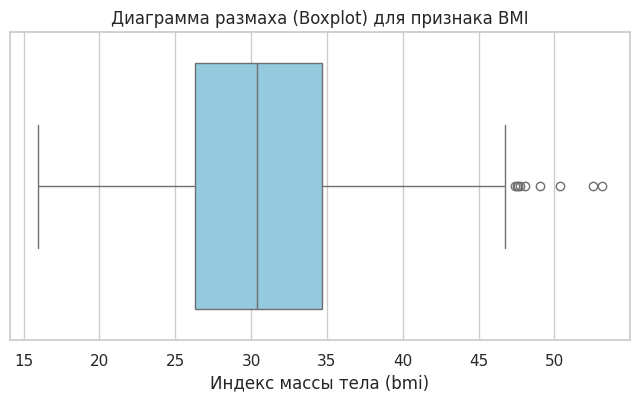

Выбросы предиктора bmi (IQR): 9 наблюдений, границы = [13.70, 47.29]
Размер очищенного датафрейма df_clean: (1328, 9)


In [5]:
print('Пропуски по столбцам:')
print(df.isnull().sum())
print(f'\nКоличество полных дубликатов: {df.duplicated().sum()}')

Q1_ch = df['charges'].quantile(0.25)
Q3_ch = df['charges'].quantile(0.75)
IQR_ch = Q3_ch - Q1_ch
upper_ch = Q3_ch + 1.5 * IQR_ch
lower_ch = Q1_ch - 1.5 * IQR_ch
outliers_ch = df[(df['charges'] < lower_ch) | (df['charges'] > upper_ch)]
print(f'\nВыбросы целевой переменной charges (IQR): {len(outliers_ch)} наблюдений, верхняя граница = {upper_ch:.2f}')

plt.figure(figsize=(8, 4))
sns.boxplot(x=df['bmi'], color='skyblue')
plt.title('Диаграмма размаха (Boxplot) для признака BMI')
plt.xlabel('Индекс массы тела (bmi)')
plt.show()

Q1_bmi = df['bmi'].quantile(0.25)
Q3_bmi = df['bmi'].quantile(0.75)
IQR_bmi = Q3_bmi - Q1_bmi
upper_bmi = Q3_bmi + 1.5 * IQR_bmi
lower_bmi = Q1_bmi - 1.5 * IQR_bmi
outliers_bmi = df[(df['bmi'] < lower_bmi) | (df['bmi'] > upper_bmi)]
print(f'Выбросы предиктора bmi (IQR): {len(outliers_bmi)} наблюдений, границы = [{lower_bmi:.2f}, {upper_bmi:.2f}]')

df_clean = df.drop_duplicates().copy()
df_clean = df_clean[(df_clean['bmi'] >= lower_bmi) & (df_clean['bmi'] <= upper_bmi)].reset_index(drop=True)
print(f'Размер очищенного датафрейма df_clean: {df_clean.shape}')

**Обоснование обработки пропусков и выбросов:**
1. **Пропуски:** Во всех столбцах пропущенные значения отсутствуют (`0`), поэтому заполнение или удаление строк по причине пропусков не требуется.
2. **Дубликаты:** В данных обнаружен 1 полный дубликат, который был удалён для исключения искажения оценок.
3. **Выбросы целевой переменной `charges`:** Метод IQR фиксирует 139 наблюдений выше верхней границы (~34.5 тыс. долларов). Анализ показывает, что эти значения принадлежат реальным случаям (преимущественно пожилые курильщики с высоким ИМТ), а не ошибкам ввода. Удаление этих строк привело бы к потере наиболее важного сегмента дорогостоящих страховых случаев, поэтому выбросы в `charges` решено **сохранить**.
4. **Выбросы предиктора `bmi`:** По графику boxplot и методу IQR выявлено 9 экстремальных значений выше верхней границы (~47.29 $\text{кг}/\text{м}^2$). Чтобы снизить влияние единичных аномально высоких значений ИМТ на коэффициенты линейной регрессии, эти наблюдения удалены.
5. Подготовленные данные сохранены в отдельный DataFrame `df_clean` и используются во всех дальнейших расчётах.

---

## 5. Описательная статистика

Рассчитаем основные статистические характеристики для целевой переменной `charges` и категориальных признаков на очищенных данных `df_clean`.

In [6]:
charges_stats = {
    'Среднее арифметическое': df_clean['charges'].mean(),
    'Медиана': df_clean['charges'].median(),
    'Минимум': df_clean['charges'].min(),
    'Первый квартиль (Q1)': df_clean['charges'].quantile(0.25),
    'Третий квартиль (Q3)': df_clean['charges'].quantile(0.75),
    'Максимум': df_clean['charges'].max(),
    'Размах': df_clean['charges'].max() - df_clean['charges'].min(),
    'Межквартильный размах (IQR)': df_clean['charges'].quantile(0.75) - df_clean['charges'].quantile(0.25),
    'Дисперсия': df_clean['charges'].var(),
    'Стандартное отклонение': df_clean['charges'].std()
}
display(pd.DataFrame.from_dict(charges_stats, orient='index', columns=['Значение']).round(2))

cat_cols = ['sex', 'smoker', 'region', 'age_group']
cat_summary = pd.DataFrame({
    'Мода': [df_clean[col].mode()[0] for col in cat_cols],
    'Уникальных значений': [df_clean[col].nunique() for col in cat_cols]
}, index=cat_cols)
display(cat_summary)

,Значение
Среднее арифметическое,1.322105e+04
Медиана,9.369620e+03
Минимум,1.121870e+03
Первый квартиль (Q1),4.744330e+03
Третий квартиль (Q3),1.660430e+04
Максимум,6.259287e+04
Размах,6.147100e+04
Межквартильный размах (IQR),1.185998e+04
Дисперсия,1.439411e+08
Стандартное отклонение,1.199755e+04


,Мода,Уникальных значений
sex,male,2
smoker,no,2
region,southeast,4
age_group,middle,3


**Интерпретация описательной статистики:**
* Среднее значение `charges` (13 221.05) заметно превышает медиану (9 369.62), что свидетельствует о сильной правосторонней асимметрии распределения (наличие группы клиентов с очень высокими расходами).
* Большое стандартное отклонение (11 997.55) и широкий размах (61 471.00) указывают на значительную неоднородность медицинских трат среди застрахованных.
* Среди категориальных признаков: преобладают мужчины (`male`, 2 уникальных значения), некурящие (`no`, 2 уникальных значения), жители юго-востока (`southeast`, 4 уникальных значения) и клиенты средней возрастной группы (`middle`, 3 уникальных значения).

---

## 6. Сравнение групп и проверка статистической гипотезы

Сравним медицинские расходы (`charges`) в двух группах по категориальному признаку `smoker` (курящие и некурящие клиенты).

Поскольку распределение `charges` имеет выраженную правостороннюю асимметрию и не подчиняется нормальному закону, для проверки равенства распределений выберем непараметрический **U-критерий Манна-Уитни**. Уровень значимости примем равным $\alpha = 0.05$.

**Формулировка гипотез:**
* $H_0$: Распределения медицинских расходов у курящих и некурящих клиентов не различаются (между группами нет статистически значимых различий).
* $H_1$: Распределения медицинских расходов у курящих и некурящих клиентов статистически значимо различаются.

In [7]:
group_stats = df_clean.groupby('smoker')['charges'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)
display(group_stats)

smokers_charges = df_clean[df_clean['smoker'] == 'yes']['charges']
nonsmokers_charges = df_clean[df_clean['smoker'] == 'no']['charges']

u_stat, p_value = stats.mannwhitneyu(smokers_charges, nonsmokers_charges, alternative='two-sided')
print(f'U-статистика Манна–Уитни: {u_stat:.2f}')
print(f'p-value: {p_value:.4e}')

,count,mean,median,std,min,max
smoker,,,,,,
no,1057,8448.60,7345.08,6002.05,1121.87,36910.61
yes,271,31835.34,34303.17,11384.54,12829.46,62592.87


U-статистика Манна–Уитни: 279044.00
p-value: 1.7815e-128


**Вывод по проверке гипотезы:**
* Средние расходы курящих (31835.34) почти в 4 раза выше средних расходов некурящих (8448.60), а медиана выше более чем в 4.5 раза.
* Рассчитанное значение $p\text{-value}$ (1.7815e-128) существенно меньше заданного уровня значимости $\alpha = 0.05$.
* Следовательно, **нулевая гипотеза $H_0$ отвергается**: различия в медицинских расходах между курящими и некурящими клиентами статистически значимы.

---

## 7. Визуализация данных

Построим отдельные графики для количественных и категориальных признаков, визуализируем распределение расходов по группам, а также создадим аналитический дашборд из трёх взаимосвязанных графиков.

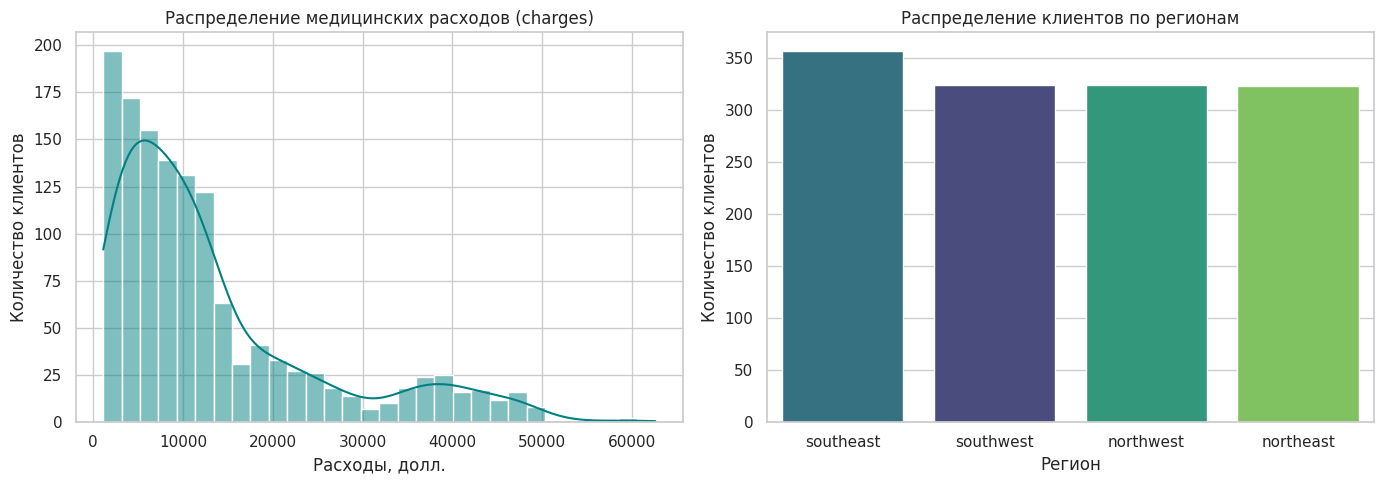

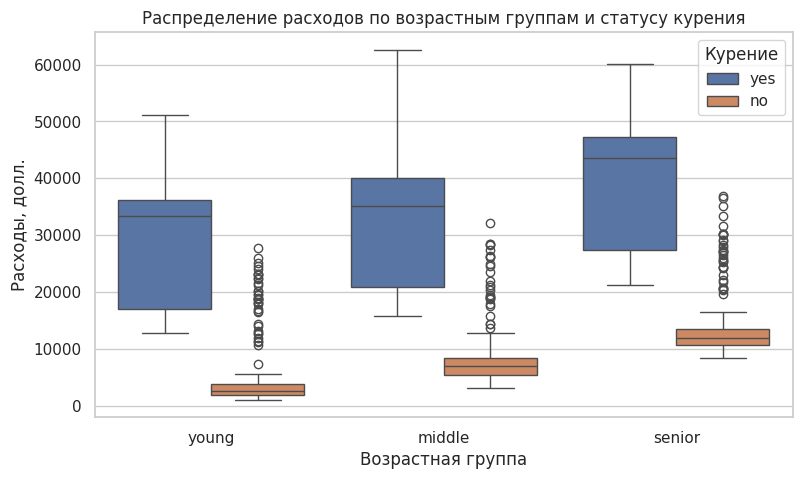

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_clean['charges'], bins=30, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Распределение медицинских расходов (charges)')
axes[0].set_xlabel('Расходы, долл.')
axes[0].set_ylabel('Количество клиентов')

sns.countplot(data=df_clean, x='region', order=df_clean['region'].value_counts().index, ax=axes[1], palette='viridis', hue='region', legend=False)
axes[1].set_title('Распределение клиентов по регионам')
axes[1].set_xlabel('Регион')
axes[1].set_ylabel('Количество клиентов')

plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x='age_group', y='charges', hue='smoker', order=['young', 'middle', 'senior'])
plt.title('Распределение расходов по возрастным группам и статусу курения')
plt.xlabel('Возрастная группа')
plt.ylabel('Расходы, долл.')
plt.legend(title='Курение')
plt.show()

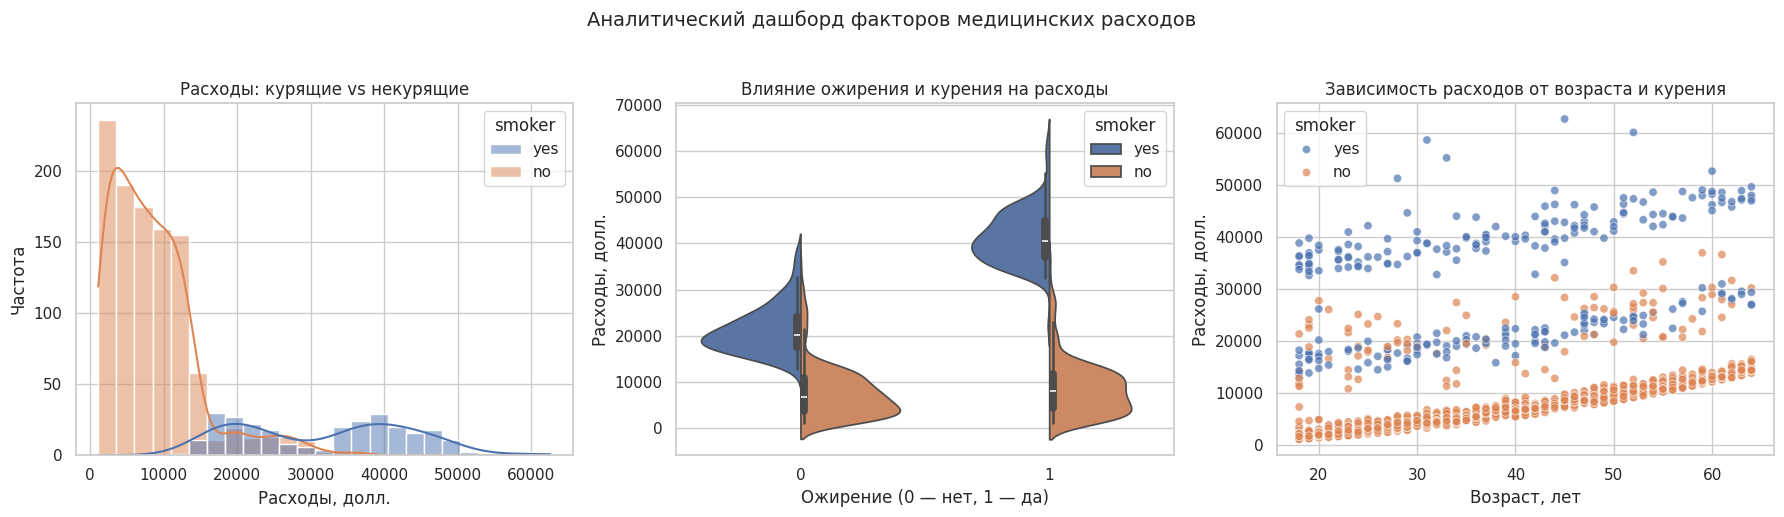

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=df_clean, x='charges', hue='smoker', bins=25, kde=True, ax=axes[0])
axes[0].set_title('Расходы: курящие vs некурящие')
axes[0].set_xlabel('Расходы, долл.')
axes[0].set_ylabel('Частота')

sns.violinplot(data=df_clean, x='is_obese', y='charges', hue='smoker', split=True, ax=axes[1])
axes[1].set_title('Влияние ожирения и курения на расходы')
axes[1].set_xlabel('Ожирение (0 — нет, 1 — да)')
axes[1].set_ylabel('Расходы, долл.')

sns.scatterplot(data=df_clean, x='age', y='charges', hue='smoker', alpha=0.7, ax=axes[2])
axes[2].set_title('Зависимость расходов от возраста и курения')
axes[2].set_xlabel('Возраст, лет')
axes[2].set_ylabel('Расходы, долл.')

plt.suptitle('Аналитический дашборд факторов медицинских расходов', fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

**Интерпретация визуализаций:**
1. Гистограмма `charges` подтверждает сильную правостороннюю асимметрию: большинство клиентов тратят до 15 тыс. долларов, но есть отдельный «хвост» от 30 до 60+ тыс. долларов.
2. Столбчатая диаграмма показывает сбалансированную выборку по всем четырём регионам.
3. Диаграмма размаха по возрастным группам и дашборд чётко выявляют **синергетический эффект**: среди курящих с ожирением (`is_obese = 1`) расходы резко скачут вверх (от 35 тыс. долларов и выше), тогда как у курящих без ожирения они чаще находятся в диапазоне 15–30 тыс. долларов.
4. На графике рассеяния `age` vs `charges` отчётливо видны три параллельные «полосы» роста трат с возрастом: нижняя (некурящие), средняя (курящие без ожирения) и верхняя (курящие с ожирением).

---

## 8. Корреляционный анализ

Исследуем линейные связи между количественными признаками набора данных `df_clean`.

Коэффициент корреляции Пирсона между age и charges: 0.3013 (p-value = 2.8323e-29)


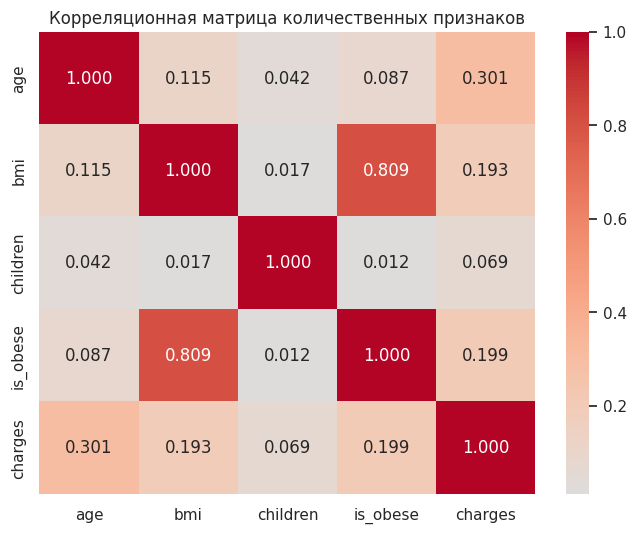

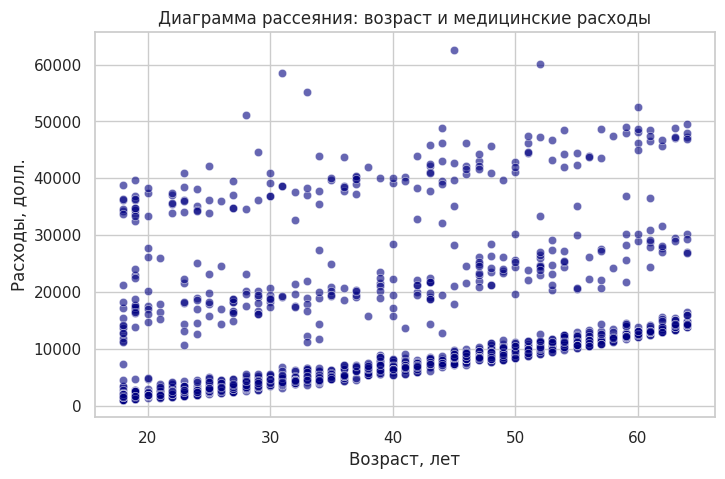

In [10]:
p_corr, p_val_corr = stats.pearsonr(df_clean['age'], df_clean['charges'])
print(f'Коэффициент корреляции Пирсона между age и charges: {p_corr:.4f} (p-value = {p_val_corr:.4e})')

num_cols = ['age', 'bmi', 'children', 'is_obese', 'charges']
corr_matrix = df_clean[num_cols].corr(method='pearson')

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', center=0)
plt.title('Корреляционная матрица количественных признаков')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x='age', y='charges', alpha=0.6, color='navy')
plt.title('Диаграмма рассеяния: возраст и медицинские расходы')
plt.xlabel('Возраст, лет')
plt.ylabel('Расходы, долл.')
plt.show()

**Выводы по корреляционному анализу:**
* Коэффициент корреляции Пирсона между возрастом (`age`) и расходами (`charges`) составляет 0.301, что соответствует **слабой положительной линейной связи**.
* **Наиболее сильная линейная связь** в матрице: между `bmi` и `is_obese` (0.809), а среди исходных независимых признаков - между `age` и `charges` (0.301).
* **Наиболее слабая линейная связь** в матрице: между `children` и `is_obese` (0.012), а среди исходных непрерывных признаков - между `children` и `bmi` (0.017).
* На диаграмме рассеяния виден положительный тренд: с возрастом минимальная планка медицинских расходов уверенно растёт, однако сильный разброс точек вверх обусловлен категориальным признаком курения, не вошедшим в матрицу количественных корреляций.

---

## 9. Линейная регрессия

Поставим задачу регрессии: предсказать величину медицинских расходов (`charges`, целевая переменная $y$) на основе характеристик клиента.

В качестве предикторов $X$ используем исходные признаки: количественные (`age`, `bmi`, `children`) и категориальные (`sex`, `smoker`, `region`), преобразованные в дамми-переменные (`drop_first=True`). Производные признаки `is_obese` и `age_group` в модель не включаются во избежание мультиколлинеарности с `bmi` и `age`. Разделим данные на обучающую (80%) и тестовую (20%) выборки.

In [11]:
features = ['age', 'bmi', 'children', 'sex', 'smoker', 'region']
X = pd.get_dummies(df_clean[features], drop_first=True, dtype=int)
y = df_clean['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

print(f'Свободный член (intercept): {model.intercept_:.2f}')
coef_df = pd.DataFrame({
    'Признак': X.columns,
    'Коэффициент': model.coef_
}).round(2)
display(coef_df)

y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

print(f'R2 на тестовой выборке: {r2:.4f}')
print(f'MSE на тестовой выборке: {mse:.2f}')
print(f'RMSE на тестовой выборке: {rmse:.2f}')
print(f'MAE на тестовой выборке: {mae:.2f}')

Свободный член (intercept): -12180.87


,Признак,Коэффициент
0,age,259.03
1,bmi,349.24
2,children,529.46
3,sex_male,-38.69
4,smoker_yes,23743.31
5,region_northwest,-574.68
6,region_southeast,-1302.61
7,region_southwest,-1549.51


R2 на тестовой выборке: 0.7448
MSE на тестовой выборке: 35465549.24
RMSE на тестовой выборке: 5955.30
MAE на тестовой выборке: 4125.94


**Уравнение полученной модели линейной регрессии:**

$$\hat{y} = \beta_0 + \beta_1 \cdot \text{age} + \beta_2 \cdot \text{bmi} + \beta_3 \cdot \text{children} + \beta_4 \cdot \text{sex\_male} + \beta_5 \cdot \text{smoker\_yes} + \beta_6 \cdot \text{region\_northwest} + \beta_7 \cdot \text{region\_southeast} + \beta_8 \cdot \text{region\_southwest}$$

С подставленными коэффициентами:

$$\hat{y} = -12180.87 + 259.03 \cdot \text{age} + 349.24 \cdot \text{bmi} + 529.46 \cdot \text{children} - 38.69 \cdot \text{sex\_male} + 23743.31 \cdot \text{smoker\_yes} - 574.68 \cdot \text{region\_northwest} - 1302.61 \cdot \text{region\_southeast} - 1549.51 \cdot \text{region\_southwest}$$

**Интерпретация коэффициентов:**
* **`smoker_yes`**: при прочих равных условиях курение увеличивает ежегодные медицинские расходы в среднем на `23 743.31` долларов - это самый мощный предиктор.
* **`age`**: каждый дополнительный год жизни увеличивает ожидаемые расходы примерно на `259.03` долларов.
* **`bmi`**: увеличение индекса массы тела на 1 единицу приводит к росту расходов в среднем на `349.24` долларов.
* **`children`**: каждый дополнительный ребёнок в полисе добавляет в среднем `529.46` долларов.
* Региональные и половые коэффициенты относительно невелики (от `-38.69` до `-1549.51`) и оказывают второстепенное влияние.

**Оценка качества модели на тестовой выборке:**
* $R^2 = 0.7448$: модель объясняет около **74.48%** дисперсии медицинских расходов на новых данных, что является хорошим показателем для базовой линейной модели.
* $MAE = 4125.94$: в среднем прогноз модели ошибается на ~`4 125.94` долларов.
* $MSE = 35\,465\,549.24$ ($RMSE \approx 5955.30$): заметное превышение $RMSE$ над $MAE$ говорит о наличии крупных ошибок на отдельных наблюдениях (в первую очередь из-за нелинейного скачка расходов при сочетании курения и ожирения).

**Вывод об использовании:** модель хорошо улавливает ключевые тренды и подходит для базовой оценки страховых рисков, однако для промышленного ценообразования её стоит улучшить за счёт добавления полиномиальных/взаимодействующих признаков (например, `smoker * bmi`) или использования нелинейных моделей (градиентный бустинг).

---

## 10. Итоговые выводы по проекту

1. В ходе исследования был проанализирован датасет медицинского страхования `insurance.csv` (1338 записей, после удаления дубликата и 9 выбросов по ИМТ - 1328 записей). Пропуски в данных отсутствуют.
2. Главным фактором, определяющим величину медицинских расходов, является **курение**: статистическая проверка с помощью критерия Манна–Уитни подтвердила значимое различие между группами ($p < 0.001$), причём курящие клиенты обходятся в среднем почти в 4 раза дороже некурящих.
3. Визуальный анализ показал синергетический эффект между курением и ожирением (`bmi >= 30`), вызывающий резкий скачок трат выше 35 тыс. долларов, а также устойчивый линейный рост минимальных расходов с возрастом.
4. Построенная модель множественной линейной регрессии объясняет около **74.5%** вариации целевой переменной на тестовой выборке ($R^2 = 0.7448$) и количественно подтверждает ключевую роль курения, возраста и индекса массы тела.